## clean the heating index and build the target

updates

In [20]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [21]:
raw = Path("../data/raw")
processed = Path("../data/processed")
output = Path("../output")
processed.mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)

## Decisions used in this notebook

| Decision | Value | Why |
|---|---|---|
| First year of the target | 2023 | Observations, time span and type. The heating index file has one row per building and year: 249,398 rows for 21,206 buildings, mainly 2011–2026. We keep one value per building, because yearly values of the same building are so similar that the model could copy the answer across training and test data. We use each building’s latest 3-year average ending in 2023 or later. Older averages would describe buildings before renovations or heating changes, and values have fallen overall (median about 490 in 2018, about 380 in 2025). Newer ones only would cost about 400 of our few houses. After cleaning (before the merge with the register features): 16,562 buildings, 1,531 of them houses. Cross-section: each building appears once.|
| Lowest plausible 3-year average | 50 MJ/m² per year | even very efficient buildings (Minergie-P) are above this; lower values point to a wrong floor area |
| Highest plausible 3-year average | 1,500 MJ/m² per year | about 3× the threshold; higher values point to data errors |
| House definition | GKLAS 1110 + 1121 (one or two dwellings) | approximates the target group (residential, fewer than 5 heat consumers): covers 95% of its 23,123 buildings; available for every building, declared or not. Agrees with the heating file's category for 74% of our houses. |



In [22]:
FIRST_YEAR = 2023
MIN_VALUE = 50
MAX_VALUE = 1500

## Cleaning the heating index

We only want the distinct buildings, hence the SCANE_INDICE_MOYENNES_3_ANS file contains buildings multiple times. 

In [23]:
idc = pd.read_csv(raw / "SCANE_INDICE_MOYENNES_3_ANS.csv", sep=";", encoding="utf-8-sig", low_memory=False)

print("Rows:", len(idc))
print("Buildings (unique EGID):", idc["EGID"].nunique())
print("Years:", idc["ANNEE"].min(), "to", idc["ANNEE"].max())

Rows: 249398
Buildings (unique EGID): 21206
Years: 0 to 2026


## Step 2 – Remove duplicates and year 0

Some building-year combinations appear more than once. We first check that the copies carry the same value;
if they do, we can safely keep one of them.

In [24]:
dup_mask = idc.duplicated(["EGID", "ANNEE"], keep=False)
dups = idc[dup_mask]
same_value = dups.groupby(["EGID", "ANNEE"])["INDICE"].nunique().eq(1).all()
print("Rows that are duplicated:", dup_mask.sum())
print("Do all copies have the same value?", same_value)

idc = idc.drop_duplicates(["EGID", "ANNEE"], keep="last")
idc = idc[idc["ANNEE"] != 0]
print("Rows after cleaning:", len(idc))

Rows that are duplicated: 1047
Do all copies have the same value? True
Rows after cleaning: 248859


## Build the target

As mentioned above we keep **one** value for each building: the most recent 3-year average from 2023 onwards.

We also keep, for later use (not as features!):
- `ref_year` – the last year of the 3-year period
- `heated_floor_area` – the heated floor area, only used to find "twin" buildings for the split.
  It must **never** be a feature: it is only known once a building has declared.
- `building_type` – the building use according to the heating file, used for the merge-loss table

In [25]:
has_avg = idc[(idc["ANNEE"] >= FIRST_YEAR) & idc["INDICE_MOY3"].notna()] #all rows whose year is 2023 or later or doesnt have a missing 3 year average
latest = has_avg.sort_values("ANNEE").drop_duplicates("EGID", keep="last") #sorting it by year and then keeping the most recent year per building
target_old = latest[["EGID", "ANNEE", "INDICE_MOY3", "SRE", "DESTINATION"]].rename(columns={
    "ANNEE": "ref_year", "INDICE_MOY3": "y", "SRE": "heated_floor_area", "DESTINATION": "building_type"})
print("Buildings with a 3-year average from", FIRST_YEAR, ":", len(target_old))
display(target_old)

Buildings with a 3-year average from 2023 : 16587


,EGID,ref_year,y,heated_floor_area,building_type
70267,1013338,2023,555.0,1377,Eglise
172708,2036675,2023,370.0,253,Habitation un logement
69988,1013417,2023,480.0,2541,Hab. - rez activités
70169,1013266,2023,517.0,1055,Habitation - activités
171981,2036972,2023,455.0,1739,Bureaux
...,...,...,...,...,...
203096,3132099,2026,314.0,810,Hab plusieurs logements
23279,1006454,2026,314.0,1069,Habitation - activités
230213,295119457,2026,156.0,1490,Hab plusieurs logements
144299,1030897,2026,212.0,1642,Habitation - activités


## implausible values

In [26]:
before = len(target_old)
target = target_old[(target_old["y"] >= MIN_VALUE) & (target_old["y"] <= MAX_VALUE)]
print("Buildings removed as implausible:", before - len(target))
print("Buildings kept:", len(target))


Buildings removed as implausible: 25
Buildings kept: 16562


## House definition

**Why houses with one or two dwellings?** The model is meant for buildings that do not have to declare their heating index: residential buildings with fewer than 5 heat consumers ("Habitation, moins de 5 preneurs de chaleur" in the cantonal declaration status file), mostly small houses and villas. We approximate this group with the register's building class for houses with one or two dwellings (GKLAS 1110 and 1121). This covers 95% of the 23,123 buildings in the group (21,906). Most of the remaining 3% are buildings with three or four dwellings, which the register puts in the same class as large apartment blocks (GKLAS 1122, three or more dwellings), so we cannot separate them by building class. We accept this small gap because the register class is available for every building, declared or not.

Models are trained on all buildings but chosen and evaluated on these houses.


We now insert all the single houses into our target using the building class from the federal building register (GKLAS 1110 and 1121, Federal Statistical Office).
We use this definition because it exists for every building, including the undeclared ones the model will be applied to. Models are trained on all buildings but chosen and evaluated on these houses.

In [27]:
register = pd.read_csv(raw / "gebaeude_batiment_edificio.csv", sep="\t", usecols=["EGID", "GKLAS"], low_memory=False)
target = target.merge(register, on="EGID", how="left")
target["house"] = target["GKLAS"].isin([1110, 1121]) #returns yes/no if it is a house according to the GKlas

print("Buildings without GKLAS:", target["GKLAS"].isna().sum())
print("Houses (1 or 2 dwellings, GKLAS 1110/1121):", target["house"].sum())


Buildings without GKLAS: 120
Houses (1 or 2 dwellings, GKLAS 1110/1121): 1531


In [28]:
# check: how well does GKLAS 1110/1121 cover the target group (fewer than 5 heat consumers)?
status = pd.read_csv(raw / "OCEN_ETAT_IDC_PUBLIC.csv", sep=";", encoding="utf-8-sig", low_memory=False)
register_all = pd.read_csv(raw / "gebaeude_batiment_edificio.csv", sep="\t", usecols=["EGID", "GKLAS"], low_memory=False)

small = status[status["DETAIL_ETAT_IDC"] == "Habitation, moins de 5 preneurs de chaleur"]
small = small.merge(register_all, on="EGID", how="left")
small_house = small["GKLAS"].isin([1110, 1121])

print("Buildings with fewer than 5 heat consumers:", len(small))
print("Of these, houses by GKLAS (1110/1121):", small_house.sum())
print("Share:", round(small_house.sum() / len(small) * 100, 1), "%")
print()
print(small["GKLAS"].value_counts(dropna=False).head(5).to_string())


Buildings with fewer than 5 heat consumers: 23123
Of these, houses by GKLAS (1110/1121): 21906
Share: 94.7 %

GKLAS
1110.0    20524
1121.0     1382
1122.0      728
NaN         389
1130.0       26


In [29]:
idc_house = target["building_type"].isin(["Habitation un logement", "Hab. deux logements"])

print("Houses by GKLAS:", target["house"].sum())
print("Houses by heating file:", idc_house.sum())
print("Houses by both:", (target["house"] & idc_house).sum())
print("Agreement:", round((target["house"] & idc_house).sum() / target["house"].sum() * 100, 1), "%")



Houses by GKLAS: 1531
Houses by heating file: 1263
Houses by both: 1133
Agreement: 74.0 %


We define a house as a building with one or two dwellings in the federal building register (GKLAS 1110 and 1121). We use the register because it covers every building, including the undeclared ones our model is meant for. As a check, we compared it with the building use in the heating file: of our 1,531 houses, 1,133 (74%) are also listed there as houses with one or two dwellings. The heating file is stricter because it records how a building is used: a house with a shop or office inside is often listed as mixed-use, while the register still classes it as a house. The other disagreements are buildings the heating file lists as offices or apartment buildings. We consider this moderate agreement acceptable: 

**the differences mostly have a clear explanation, and the houses the two sources disagree on have a similar median heating index (406 vs. 415 MJ/m² per year), so they should not distort our results much.**

## Heating during the target years

The register shows **today's** heating system. We check whether a building had the
same heating **while its target value was measured**. The heating file records the energy source for every
year (`AGENT_ENERGETIQUE_1`), so we can check this directly.

**What we do:**

1. **Simplify the labels.** `energy_group_from_idc` turns the detailed French labels into 7 groups:
   gas, oil, district heat, heat pump, wood, electric and other. Missing labels go into "other".
2. **Look only at the target years.** For each building we keep the 3 years that make up its 3-year average
   (`ref_year - 2` to `ref_year`).
3. **Find buildings that switched.** A building switched if it has more than one energy group in those 3 years.
4. **Count the switches for houses.** Houses are buildings with one or two dwellings in the register
   (GKLAS 1110 and 1121). 65 of 1,531 houses switched. We also show what they switched from and to.
5. **Drop all buildings that switched.** Their target value mixes two heating systems, so it does not describe
   either one well. Since only 65 of 1,531 houses are affected, we lose little data.
6. **Keep each building's energy group** as `energy_target_period`. After the drop, every building has the
   same group in all 3 years, so we simply take that one value. 

**Note:** not every switch is a real change of heating system. The most common ones are "Autre" → heat pump
(15 houses) and shared district heating ("CAD réparti") → oil (12 houses), where the heating index barely
changes. These look more like changes in how the energy source was recorded. We drop them anyway to be safe;
this costs 65 of 1,531 houses.



In [30]:
def energy_group_from_idc(label):
    label = str(label)
    if label.startswith("Gaz"):
        return "gas"
    if label.startswith("Mazout"):
        return "oil"
    if label.startswith("CAD") or label.startswith("Chauffage"):
        return "district heat"
    if "PAC" in label:
        return "heat pump"
    if label.startswith("Bois"):
        return "wood"
    if label.startswith("Électricité directe"):
        return "electric"
    return "other"

rows = idc.merge(target[["EGID", "ref_year"]], on="EGID")  # add each building's ref_year to all its yearly rows (as a column)
rows = rows[(rows["ANNEE"] <= rows["ref_year"]) & (rows["ANNEE"] >= rows["ref_year"] - 2)]  # keep only the 3 years of the target average
rows["energy_group"] = rows["AGENT_ENERGETIQUE_1"].map(energy_group_from_idc) #replaces french word w english word

# picking the energy group in each building's 3-year window to know which heating source it is using (see print), (same in all years once switchers are dropped)
energy_target = rows.groupby("EGID")["energy_group"].first().rename("energy_target_period")
target = target.merge(energy_target, on="EGID", how="left")

# buildings that switched energy group within their 3-year window
groups_per_building = rows.groupby("EGID")["energy_group"].nunique() #counts the number of different heating sources per building
switched = groups_per_building[groups_per_building > 1].index #checks if there is more than one different heating source
target["switched"] = target["EGID"].isin(switched) #adds column in target and returns true or false for every single houses 

# houses (GKLAS 1110/1121, from the register)
houses = target["house"]
switched_houses = target.loc[houses & target["switched"], "EGID"] #find the EGIDs of the houses that switched energy source


# what the switched houses changed from and to (first year → last year of the window)
sw = rows[rows["EGID"].isin(switched_houses)].sort_values("ANNEE")
from_to = sw.groupby("EGID")["energy_group"].agg(lambda s: s.iloc[0] + " → " + s.iloc[-1])

print(target["energy_target_period"].value_counts().to_string())
print()
print("Single houses:", houses.sum())
print("Single houses that switched:", len(switched_houses))
print("Share of single houses that switched:", round(target.loc[houses, "switched"].mean() * 100, 1), "%")
print()
print(from_to.value_counts().head(5).to_string())


before = len(target)
houses_before = target["house"].sum()
target = target[target["switched"] == False]
print()
print("Buildings that switched:", before - len(target))
print("Buildings left:", len(target), "| Single houses left:", target["house"].sum())
print()
print(target["energy_target_period"].value_counts().to_string())
print("Houses with other in their switch:", from_to.str.contains("other").sum())



energy_target_period
gas              9039
oil              3994
district heat    2494
heat pump         667
wood              228
other              88
electric           52

Single houses: 1531
Single houses that switched: 65
Share of single houses that switched: 4.2 %

energy_group
other → heat pump      16
district heat → oil    13
gas → heat pump         9
oil → heat pump         6
gas → gas               4

Buildings that switched: 701
Buildings left: 15861 | Single houses left: 1466

energy_target_period
gas              8799
oil              3831
district heat    2326
heat pump         615
wood              209
electric           50
other              31
Houses with other in their switch: 20


,count,median
ANNEE,,
2011,15626,499.0
2012,16061,508.0
2013,16245,511.0
2014,16260,495.0
2015,15851,490.0
2016,15819,477.0
2017,15817,476.0
2018,15902,486.0
2019,15941,470.0



Target by reference year:
          count  median
ref_year               
2023        786   423.5
2024       1353   409.0
2025       7602   389.0
2026       6120   382.0


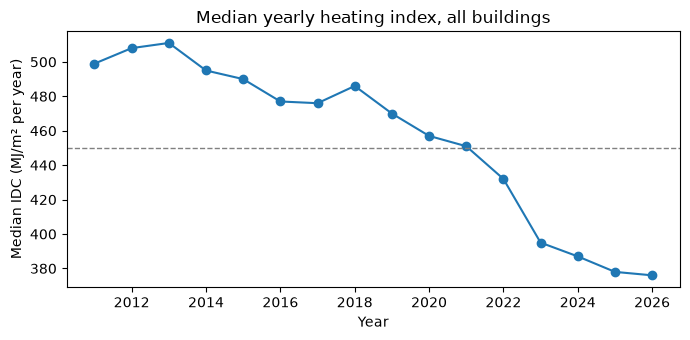

In [31]:
plausible_yearly = idc[(idc["INDICE"] > 0) & (idc["INDICE"] < 2000)]
by_year = plausible_yearly.groupby("ANNEE")["INDICE"].agg(["count", "median"]).loc[2011:]
display(by_year)
by_ref = target.groupby("ref_year")["y"].agg(["count", "median"])
print("\nTarget by reference year:")
print(by_ref.to_string())

fixed_2025 = has_avg[has_avg["ANNEE"] == 2025]
fixed_2025 = fixed_2025[(fixed_2025["INDICE_MOY3"] >= MIN_VALUE) & (fixed_2025["INDICE_MOY3"] <= MAX_VALUE)]
fixed_2025 = fixed_2025.merge(register, on="EGID", how="left")


fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(by_year.index, by_year["median"], marker="o")
ax.axhline(450, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Year")
ax.set_ylabel("Median IDC (MJ/m² per year)")
ax.set_title("Median yearly heating index, all buildings")
fig.tight_layout()
fig.savefig(output / "year_effect.png", dpi=150)


## Year effect

Heating index values have fallen over time: the median yearly value across all buildings dropped from about 499 in 2011 to about 376 in 2026 (see the plot above). Our target mixes 3-year averages ending in different years (2023 to 2026), so we check whether this trend shows up in the target.

**Result:** buildings whose period ends in 2023 have a median target of 423.5, those ending in 2026 a median of 382, a difference of about 41.5. This is a real change over time, not just a difference between buildings: for the 6120 buildings whose latest period ends in 2026, ** the median of their own 3-year average fell by 31 between the period ending in 2023 and the one ending in 2025. For houses, there is no clear pattern; the groups are small and the medians go up and down. **

**Decision:** we keep periods ending in 2023 or later (option A). Using only periods ending in 2025 (option B) would remove the year effect but cost about 400 of our houses. Since 87% of our targets end in 2025 or 2026, the effect on our data is small. However, buildings with older targets may have values that are slightly too high compared with today. We mention this as a limitation in the report.


In [32]:
# save the final target for the next notebooks
target_finished = target.drop(columns="switched")  # all remaining buildings have switched = False, so the column is not needed
target_finished.to_csv(processed / "target.csv", index=False)

# table for the merge-loss count (task 7): one row per building in the heating file, one column per step
merge_loss = idc.sort_values("ANNEE").drop_duplicates("EGID", keep="last")[["EGID", "DESTINATION"]]
merge_loss = merge_loss.rename(columns={"DESTINATION": "building_type"})
merge_loss = merge_loss.merge(register, on="EGID", how="left")
merge_loss["house"] = merge_loss["GKLAS"].isin([1110, 1121])

plausible_buildings = target_old[(target_old["y"] >= MIN_VALUE) & (target_old["y"] <= MAX_VALUE)]
merge_loss["has_target"] = merge_loss["EGID"].isin(target_old["EGID"])           # has a 3-year average from FIRST_YEAR on
merge_loss["plausible"] = merge_loss["EGID"].isin(plausible_buildings["EGID"])   # value between 50 and 1500
merge_loss["kept"] = merge_loss["EGID"].isin(target_finished["EGID"])                 # did not switch energy source

merge_loss.to_csv(processed / "merge_loss.csv", index=False)

print("Saved target.csv with", len(target_finished), "buildings")
print("Saved merge_loss.csv with", len(merge_loss), "buildings")
print()

# counts per step (b = buildings, h = houses)
all_b = len(merge_loss)
all_h = merge_loss["house"].sum()
target_b = merge_loss["has_target"].sum()
target_h = (merge_loss["has_target"] & merge_loss["house"]).sum()
plaus_b = merge_loss["plausible"].sum()
plaus_h = (merge_loss["plausible"] & merge_loss["house"]).sum()
kept_b = merge_loss["kept"].sum()
kept_h = (merge_loss["kept"] & merge_loss["house"]).sum()

print("All buildings in the idc file:")
print("   ", all_b, "buildings,", all_h, "houses")
print("Number of Buildings with a 3-year average ending in", FIRST_YEAR, "or later:")
print("   ", target_b, "buildings,", target_h, "houses  (removed:", all_b - target_b, "buildings,", all_h - target_h, "houses)")
print("Number of Buildings with a value between", MIN_VALUE, "and", MAX_VALUE, ":")
print("   ", plaus_b, "buildings,", plaus_h, "houses  (removed:", target_b - plaus_b, "buildings,", target_h - plaus_h, "houses)")
print("Number of buildings after removing the buildings that switched energy source:")
print("   ", kept_b, "buildings,", kept_h, "houses  (removed:", plaus_b - kept_b, "buildings,", plaus_h - kept_h, "houses)")


Saved target.csv with 15861 buildings
Saved merge_loss.csv with 21206 buildings

All buildings in the idc file:
    21206 buildings, 3879 houses
Number of Buildings with a 3-year average ending in 2023 or later:
    16587 buildings, 1532 houses  (removed: 4619 buildings, 2347 houses)
Number of Buildings with a value between 50 and 1500 :
    16562 buildings, 1531 houses  (removed: 25 buildings, 1 houses)
Number of buildings after removing the buildings that switched energy source:
    15861 buildings, 1466 houses  (removed: 701 buildings, 65 houses)
